# Rasterio

In [1]:
import os
import numpy as np
import rasterio as rio
from rasterio.plot import show, show_hist

print(rio.__version__)

1.5.2


## Odpiranje rastra

In [2]:
dem_path=os.path.normpath(r"C:\KODA\Python\Rsterio\Pivola.tif")

with rio.open(dem_path) as src:
    print(src.count)     #število kanalov (1 ker je dem)
    print(src.meta)      #meta podatki
    band=src.read(1)
    print(type(band))   #kanal je shranjen kot array
    print(band)

1
{'driver': 'GTiff', 'dtype': 'float32', 'nodata': 9999.0, 'width': 4000, 'height': 4000, 'count': 1, 'crs': CRS.from_wkt('PROJCS["ETRS89-SVN [D96] / Slovene National Grid",GEOGCS["ETRS89-SVN [D96]",DATUM["Slovenia_Geodetic_Datum_1996",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6765"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4765"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",-5000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3794"]]'), 'transform': Affine(0.5, 0.0, 548000.0,
       0.0, -0.5, 153000.49)}
<class 'numpy.ndarray'>
[[369.0252  368.90106 368.63956 ... 272.79684 272.7977  272.79935]
 [368.81174 368.63867 368.4972  ... 272.78122 272.771   2

## Prikaz rastra

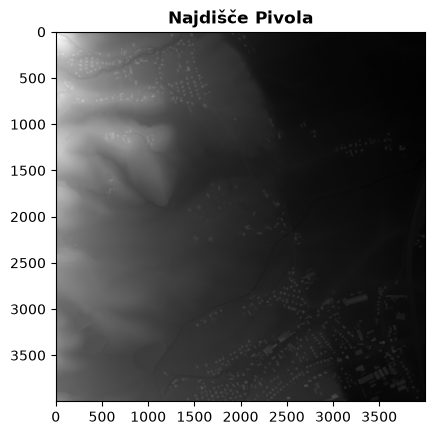

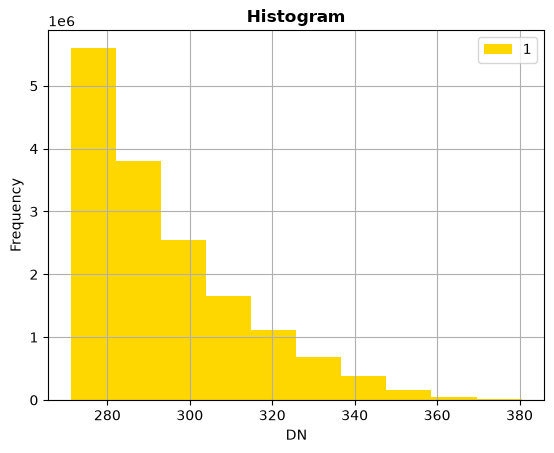

In [ ]:
show(band,title="Najdišče Pivola", cmap="gray")
show_hist(band)  #za prikaz histograma

[[-1.8488159e+00 -1.9060974e+00 -1.8838501e+00 ... -4.3640137e-03
  -6.5307617e-03  1.1444092e-02]
 [-2.0512695e+00 -2.1433411e+00 -2.1957703e+00 ...  1.5411377e-02
  -6.7749023e-03  1.1901855e-03]
 [-2.2781677e+00 -2.3053284e+00 -2.2629089e+00 ... -1.4221191e-02
   3.6010742e-03  5.1544189e-02]
 ...
 [ 3.7216187e-01  3.7393188e-01  3.5586548e-01 ... -3.0792236e-02
  -4.3792725e-02 -6.6528320e-03]
 [ 4.0930176e-01  4.2102051e-01  4.1287231e-01 ... -2.7770996e-02
  -3.0761719e-02 -1.3702393e-02]
 [ 5.0814819e-01  4.9987793e-01  4.9169922e-01 ... -2.4780273e-02
  -2.7801514e-02 -2.0874023e-02]]


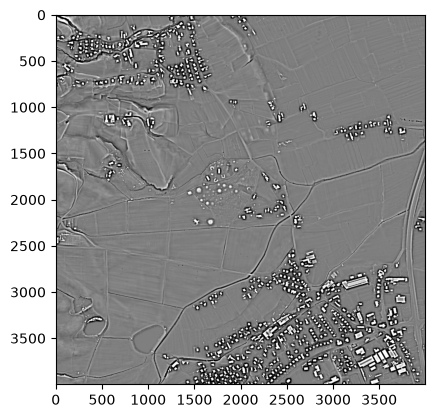

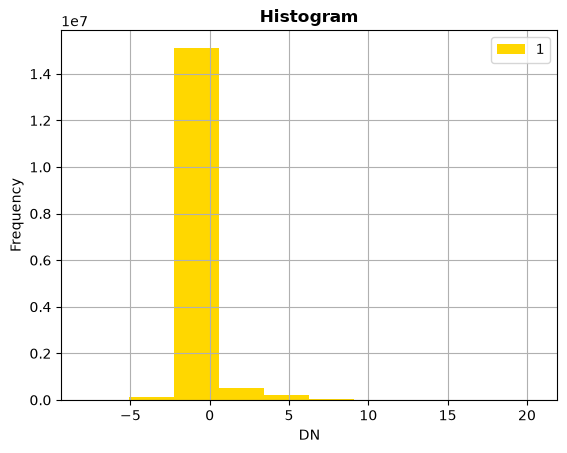

In [33]:

#Deluje isto za slrm
with rio.open(r"C:\KODA\Python\Rsterio\Pivola_SLRM_R20.tif")as src_slrm:
    slrm_band=src_slrm.read(1)

print(slrm_band)
show(slrm_band,cmap="gray", vmin=-1.5, vmax=1.5) # vmin in vmax za razteg histograma
show_hist(slrm_band)

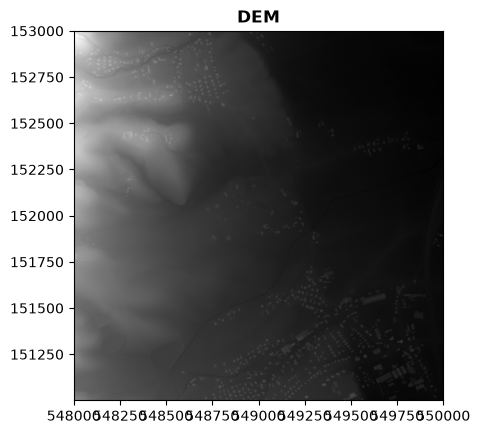

In [35]:
with rio.open(dem_path) as src:
    show(src,title="DEM", cmap="gray")  # če želimo prave koordinate, namreč izven open blocka se podatki zaprejo
    

## Transformiranje iz pixel koordinat v prostorke koordinate


### Iz pixel koordinat v prostorske
v rastru so višine (v primerudem-a) v arreyu. Da dobimo prostorske koordinate namesto koordinat v arrayu (vrstica, stolpec) naredimo nasledni postopek.

`transform*(column, row)`

`transform` pove številke za konverzijo:

The six numbers in `transform`  are a, b, c, d, e, f:

- a = pixel width in map units (0.5 m)
- e = pixel height, negative because rows count downward while northing counts upward
- c = x coordinate of the top-left corner of the raster
- f = y coordinate of the top-left corner
- b, d = rotation terms, almost always 0

### Iz prostorskih koordinat v pixel

`src.index*(prostorke koordinate)`

rezultat je (row,column)







In [43]:
with rio.open(dem_path) as src:
    transform=src.transform
    index_src=src.index
    print(src.crs)
    print(transform)
    print(index_src)

koordinate_pixel=(2445, 1618) #column , row
prostorske_koordinate=transform*koordinate_pixel

print(f"Prostorske koordinate:{prostorske_koordinate}")

koordinate_pixel_nazaj=src.index(prostorske_koordinate[0],prostorske_koordinate[1])
print(f"pixel koordinate: {koordinate_pixel_nazaj}")


EPSG:3794
| 0.50, 0.00, 548000.00|
| 0.00,-0.50, 153000.49|
| 0.00, 0.00, 1.00|
<bound method TransformMethodsMixin.index of <open DatasetReader name='C:\KODA\Python\Rsterio\Pivola.tif' mode='r'>>
Prostorske koordinate:(549222.5, 152191.49)
pixel koordinate: (1618, 2445)


## Kreiranje kompozitov

['C:\\KODA\\Python\\Rsterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B02_(Raw).tiff', 'C:\\KODA\\Python\\Rsterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B03_(Raw).tiff', 'C:\\KODA\\Python\\Rsterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B04_(Raw).tiff', 'C:\\KODA\\Python\\Rsterio\\Browser_images\\2026-10-06-00_00_2026-10-06-23_59_Sentinel-2_L2A_B08_(Raw).tiff']
{'rdeč': array([[2012, 2110, 1881, ..., 3840, 3735, 3722],
       [2150, 2287, 1940, ..., 3585, 3840, 4319],
       [2071, 2156, 1953, ..., 3834, 4456, 5223],
       ...,
       [1304, 1330, 1271, ..., 8244, 8179, 7904],
       [1357, 1363, 1324, ..., 8172, 8153, 7923],
       [1252, 1258, 1271, ..., 8277, 8284, 7989]],
      shape=(614, 987), dtype=uint16), 'zelen': array([[3172, 3454, 3336, ..., 3827, 3657, 3631],
       [3401, 3631, 3598, ..., 3716, 3867, 4155],
       [3565, 3500, 3454, ..., 3958, 4469, 4954],
       ...,
       [2307, 2313, 2248, .

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..56904].


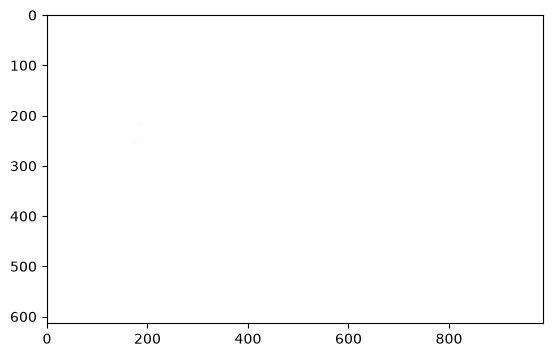

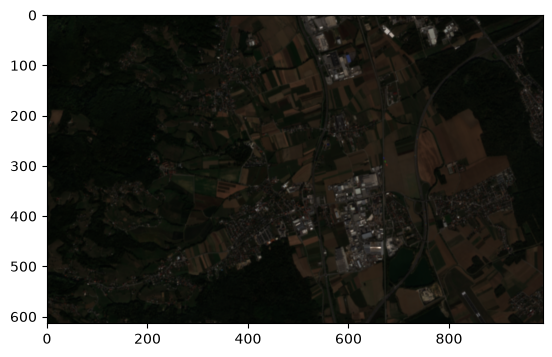

<Axes: >

In [ ]:
import glob #knjižnica za iskanje fajlov(z wildcardi ipd.)
raster_dir=os.path.normpath(r"C:\KODA\Python\Rsterio\Browser_images")

rastri=sorted(glob.glob(os.path.join(raster_dir,"*.tiff")))
print(rastri)


fajli={
    "rdeč":rastri[2],
    "zelen":rastri[1],
    "moder":rastri[0],
    "nir":rastri[3],
}

def preberi_kanal(fajl_path):                     #samo spremeni kanal v array
    with rio.open(fajl_path) as dataset:
        return dataset.read(1)


kanali={}
for fajl in fajli:                               #uporabi preberi_kanal funkcijo na vseh različnih kanalih med fajli
    kanali[fajl]=preberi_kanal(fajli[fajl])

print(kanali)

rgb_kompozit=np.stack((kanali["rdeč"], kanali["zelen"],kanali["moder"]))

def normaliziraj(array: np.ndarray):                                #Zaradi visokih vrednosti je potrebna normalizacija
    return (array-array.min())/(array.max()-array.min())


rgb_normaliziran=normaliziraj(rgb_kompozit)
show(rgb_normaliziran)


#Končal na 50 min